###Research Question and Hypothesis
Research Question: How well can age, resting blood pressure, and cholesterol levels predict a patient’s maximum heart rate using deep learning regression models?

Hypothesis: Age, resting blood pressure, and cholesterol levels can help predict maximum heart rate, but the accuracy may vary depending on the deep learning model used.

Purpose: The purpose of this project is to use deep learning regression models to predict maximum heart rate and compare their performance using the heart disease dataset.

In [85]:
import pandas as pd
import numpy as np

In [86]:
# Load the heart disease dataset
df = pd.read_csv("heart disease (1).csv")

# Preview the first five rows
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [87]:
# Check the size of the dataset
print("Number of patients:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

Number of patients: 918
Number of columns: 12

Column names:
['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']


In [88]:
# Check for missing values
print(df.isnull().sum())

# Check for zero cholesterol values
print("Zero cholesterol values:", (df["Cholesterol"] == 0).sum())

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64
Zero cholesterol values: 172


In [89]:
print("Zero resting blood pressure values:", (df["RestingBP"] == 0).sum())

Zero resting blood pressure values: 1


In [90]:
# Check for missing values
print("Missing values:")
print(df.isnull().sum())

# Check for duplicate records
print("\nDuplicate records:")
print(df.duplicated().sum())

Missing values:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

Duplicate records:
0


In [91]:
# Summarize the numerical columns
df.describe()


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [92]:
from sklearn.model_selection import train_test_split

# Select predictors and target
features = ["Age", "RestingBP", "Cholesterol"]
X = df[features].copy()
y = df["MaxHR"]

# Split before calculating replacement values
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42
)

print("Training patients:", len(X_train))
print("Testing patients:", len(X_test))

Training patients: 734
Testing patients: 184


In [93]:
# Count suspicious zero values
print("Zero blood pressure values:",
(df["RestingBP"] == 0).sum())

print("Zero cholesterol values:",
(df["Cholesterol"] == 0).sum())

Zero blood pressure values: 1
Zero cholesterol values: 172


In [94]:
# Treat invalid zeros as missing values
for column in ["Cholesterol", "RestingBP"]:
    X_train[column] = X_train[column].replace(0, np.nan)
    X_test[column] = X_test[column].replace(0, np.nan)

# Calculate replacement values from training data only
training_medians = X_train.median()

# Apply the same training medians to both datasets
X_train = X_train.fillna(training_medians)
X_test = X_test.fillna(training_medians)

print("Training medians:")
print(training_medians)
print("Missing values after cleaning:")
print(X_train.isnull().sum())
print(X_test.isnull().sum())



Training medians:
Age             54.0
RestingBP      130.0
Cholesterol    237.0
dtype: float64
Missing values after cleaning:
Age            0
RestingBP      0
Cholesterol    0
dtype: int64
Age            0
RestingBP      0
Cholesterol    0
dtype: int64


In [95]:
from sklearn.preprocessing import StandardScaler

# Scale features using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (734, 3)
Testing data shape: (184, 3)


In [96]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Set seed for reproducibility
tf.keras.utils.set_random_seed(42)

# Build a neural network to predict maximum heart rate
model_nn = keras.Sequential([
    layers.Input(shape=(3,)),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1)
])

# Configure the regression model
model_nn.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

# Display the model architecture
model_nn.summary()


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 32)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673 (2.63 KB)

 Trainable params: 673 (2.63 KB)

 Non-trainable params: 0 (0.00 B)

In [71]:
# Train the neural network using the training data
history = model_nn.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

# Display the final training results
print("Final training loss:", history.history["loss"][-1])
print("Final validation loss:", history.history["val_loss"][-1])
print("Final training MAE:", history.history["mae"][-1])
print("Final validation MAE:", history.history["val_mae"][-1])


Final training loss: 603.9878540039062
Final validation loss: 435.0245666503906
Final training MAE: 20.39373016357422
Final validation MAE: 16.971851348876953


In [72]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict maximum heart rate on unseen test data
y_pred_nn = model_nn.predict(X_test_scaled).flatten()

# Calculate regression performance
mae_nn = mean_absolute_error(y_test, y_pred_nn)
rmse_nn = np.sqrt(mean_squared_error(y_test, y_pred_nn))
r2_nn = r2_score(y_test, y_pred_nn)

print("Neural Network Test Results")
print("MAE:", round(mae_nn, 2))
print("RMSE:", round(rmse_nn, 2))
print("R-squared:", round(r2_nn, 3))

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
Neural Network Test Results
MAE: 21.28
RMSE: 26.39
R-squared: -0.045


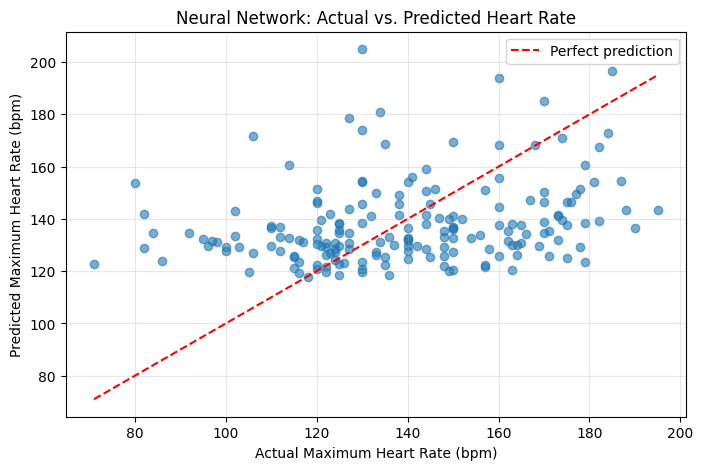

In [73]:
import matplotlib.pyplot as plt

# Compare actual and predicted maximum heart rates
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_nn, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual Maximum Heart Rate (bpm)")
plt.ylabel("Predicted Maximum Heart Rate (bpm)")
plt.title("Neural Network: Actual vs. Predicted Heart Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


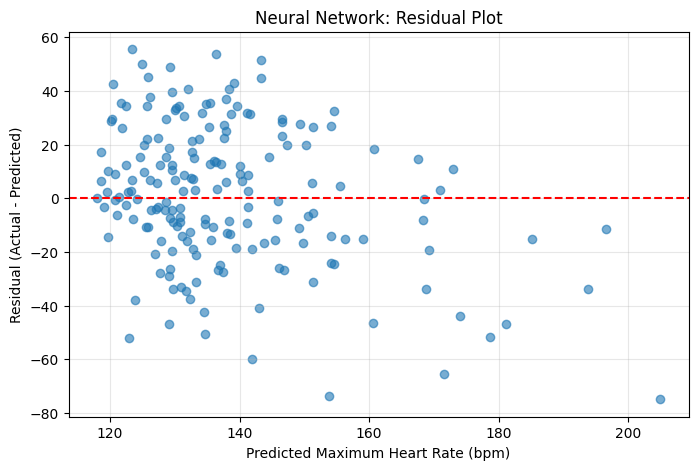

In [74]:
import matplotlib.pyplot as plt

# Calculate prediction errors
residuals = y_test - y_pred_nn

# Plot residuals against predicted heart rate
plt.figure(figsize=(8, 5))
plt.scatter(y_pred_nn, residuals, alpha=0.6)

# Reference line for zero error
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Maximum Heart Rate (bpm)")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Neural Network: Residual Plot")
plt.grid(alpha=0.3)
plt.show()

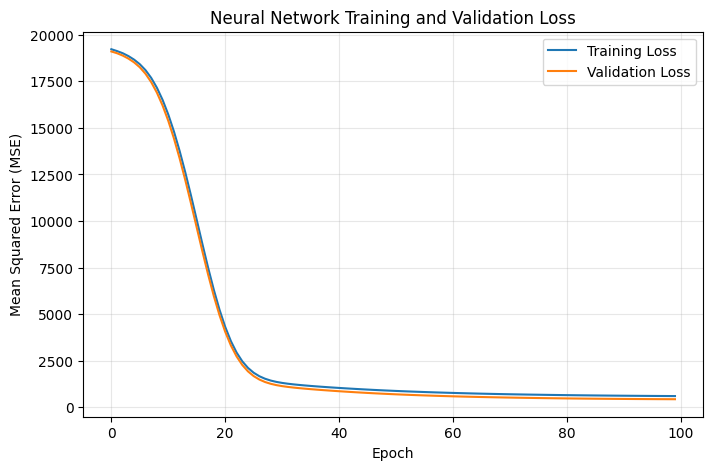

In [75]:
# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Neural Network Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [76]:
# Find the epoch with the lowest validation loss
best_epoch = np.argmin(history.history["val_loss"]) + 1

print("Best epoch:", best_epoch)
print("Lowest validation loss:",
    round(min(history.history["val_loss"]), 2))
print("Final validation loss:",
    round(history.history["val_loss"][-1], 2))


Best epoch: 100
Lowest validation loss: 435.02
Final validation loss: 435.02


In [77]:
# Add more patient characteristics to the model
features_more = [
    "Age", "RestingBP", "Cholesterol",
    "Sex", "ChestPainType", "FastingBS",
    "RestingECG", "ExerciseAngina",
    "Oldpeak", "ST_Slope"
]

# Convert categorical variables into numerical columns
X_more = pd.get_dummies(
    df[features_more],
    drop_first=True,
    dtype=int
)

y_more = df["MaxHR"]

print("Number of predictors:", X_more.shape[1])
print("Number of patients:", X_more.shape[0])


Number of predictors: 14
Number of patients: 918


In [78]:
# Split the expanded dataset into training and testing sets
from sklearn.model_selection import train_test_split

X_train_more, X_test_more, y_train_more, y_test_more = train_test_split(
    X_more,
    y_more,
    test_size=0.2,
    random_state=42
)

print("Training patients:", len(X_train_more))
print("Testing patients:", len(X_test_more))


Training patients: 734
Testing patients: 184


In [79]:
# Replace invalid zero measurements with missing values
for column in ["Cholesterol", "RestingBP"]:
    X_train_more[column] = X_train_more[column].replace(0, np.nan)
    X_test_more[column] = X_test_more[column].replace(0, np.nan)

# Calculate medians using training data only
medians_more = X_train_more.median()

# Apply training medians to both datasets
X_train_more = X_train_more.fillna(medians_more)
X_test_more = X_test_more.fillna(medians_more)

# Verify that cleaning was successful
print("Missing training values:", X_train_more.isnull().sum().sum())
print("Missing testing values:", X_test_more.isnull().sum().sum())



Missing training values: 0
Missing testing values: 0


In [80]:
from sklearn.preprocessing import StandardScaler

# Fit the scaler using training data only
scaler_more = StandardScaler()

X_train_more_scaled = scaler_more.fit_transform(X_train_more)

# Apply the same scaling to testing data
X_test_more_scaled = scaler_more.transform(X_test_more)

print("Training shape:", X_train_more_scaled.shape)
print("Testing shape:", X_test_more_scaled.shape)

Training shape: (734, 14)
Testing shape: (184, 14)


In [81]:
import tensorflow as tf
from tensorflow import keras

# Set a random seed for reproducibility
tf.keras.utils.set_random_seed(42)

# Build a neural network using 14 predictors
model_more = keras.Sequential([
    keras.layers.Input(shape=(14,)),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(1)
])

# Prepare the model for regression
model_more.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# Display the model structure
model_more.summary()


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                │ (None, 32)             │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,025 (4.00 KB)

 Trainable params: 1,025 (4.00 KB)

 Non-trainable params: 0 (0.00 B)

In [82]:
# Train the improved neural network
history_more = model_more.fit(
    X_train_more_scaled,
    y_train_more,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

# Display final training results
print("Final training loss:", round(history_more.history["loss"][-1], 2))
print("Final validation loss:", round(history_more.history["val_loss"][-1], 2))
print("Final training MAE:", round(history_more.history["mae"][-1], 2))
print("Final validation MAE:", round(history_more.history["val_mae"][-1], 2))


Final training loss: 401.53
Final validation loss: 486.61
Final training MAE: 16.3
Final validation MAE: 16.9


In [83]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict maximum heart rate on unseen test data
y_pred_more = model_more.predict(
    X_test_more_scaled
).flatten()

# Calculate test performance
mae_more = mean_absolute_error(y_test_more, y_pred_more)
rmse_more = np.sqrt(mean_squared_error(y_test_more, y_pred_more))
r2_more = r2_score(y_test_more, y_pred_more)

print("Improved Neural Network Test Results")
print("MAE:", round(mae_more, 2))
print("RMSE:", round(rmse_more, 2))
print("R-squared:", round(r2_more, 3))



6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
Improved Neural Network Test Results
MAE: 19.62
RMSE: 25.23
R-squared: 0.045


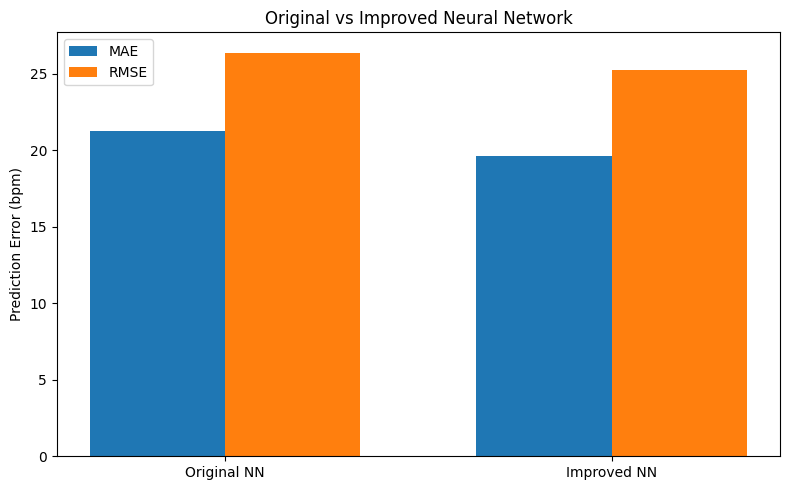

In [84]:
import matplotlib.pyplot as plt

models = ["Original NN", "Improved NN"]
mae_values = [mae_nn, mae_more]
rmse_values = [rmse_nn, rmse_more]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width/2, mae_values, width, label="MAE")
plt.bar(x + width/2, rmse_values, width, label="RMSE")

plt.xticks(x, models)
plt.ylabel("Prediction Error (bpm)")
plt.title("Original vs Improved Neural Network")
plt.legend()
plt.tight_layout()
plt.show()

###Model Comparison and Interpretation
The original neural network used three predictors: age, resting blood pressure, and cholesterol. The improved neural network used 14 predictors to estimate patients’ maximum heart rates.

The improved model performed better on the testing dataset. Its mean absolute error (MAE) decreased from 21.28 to 19.62 beats per minute, while its root mean squared error (RMSE) decreased from 26.39 to 25.23. The R-squared value also improved from -0.045 to 0.045.

These results suggest that including additional patient characteristics helped improve prediction accuracy. However, the improved model explained only 4.5% of the variation in maximum heart rate. This means the model still has limited predictive ability and should not be used by itself to make clinical decisions.

###Step 5: Act – Recommendations and Next Steps
The results show that the improved neural network performed better than the original model when predicting maximum heart rate. Adding more patient characteristics reduced prediction errors, but the model’s overall accuracy is still limited.

Based on these findings, I recommend exploring additional health-related variables, testing different neural network settings, and using a larger, more diverse dataset to improve predictions.

In a healthcare setting, this model could support future research, but it should not be used independently to make medical decisions because its predictions are not reliable enough.

The next step would be to improve the model, evaluate it using new patient data, and compare its performance with other machine learning methods before considering any practical healthcare application.